## Partie 1 — Données

Objectif de cette partie : comprendre le jeu de données, mesurer sa répartition, puis le charger proprement pour l'entraînement Keras. Le code est découpé en petites étapes, chacune avec son rôle.

### 1.1 D'où vient FER-2013 ?

**FER-2013** (*Facial Expression Recognition 2013*) a été constitué par Pierre-Luc Carrier et Aaron Courville (Université de Montréal) pour un défi Kaggle du workshop *Challenges in Representation Learning* de la conférence ICML 2013.

Constitution :

- les images ont été collectées automatiquement avec la recherche d'images Google, à partir de mots-clés liés aux émotions ;
- les visages ont été détectés, recadrés et centrés automatiquement ;
- chaque visage a été converti en **niveaux de gris** et ramené à **48×48 pixels** ;
- chaque image porte une des **7 émotions** : 0 colère, 1 dégoût, 2 peur, 3 joie, 4 tristesse, 5 surprise, 6 neutre.

Le jeu original est un fichier CSV (`fer2013.csv`) : une ligne par image, avec le label, les 2 304 pixels, et une colonne `Usage` qui fixe le découpage : `Training` (28 709 images), `PublicTest` (3 589) et `PrivateTest` (3 589).

La version utilisée ici (Kaggle, `msambare/fer2013`) contient les mêmes images, converties en JPEG et rangées en un dossier par émotion. Notre dossier `test` regroupe `PublicTest` et `PrivateTest` : on le vérifie plus bas grâce aux noms de fichiers.

Limites connues, utiles pour interpréter nos résultats :

- les labels sont bruités (collecte automatique) : les auteurs estiment la précision humaine à environ **65 % ± 5 %** sur ce jeu ;
- le gagnant du défi a obtenu environ 71 % d'accuracy ;
- les classes sont déséquilibrées (on le mesure ci-dessous).

**Référence :** I. Goodfellow et al., *Challenges in Representation Learning: A report on three machine learning contests*, ICONIP 2013 ([arXiv:1307.0414](https://arxiv.org/abs/1307.0414)).

**Licence :** pas de licence open source explicite. Le jeu est diffusé pour la recherche via la compétition Kaggle d'origine ; nous l'utilisons uniquement dans un cadre académique et ne le redistribuons pas (les images ne sont pas dans le dépôt git).

### 1.2 Imports et constantes

On utilise des outils classiques :

- `pathlib` pour lister les fichiers ;
- **OpenCV** (`cv2`) pour lire et transformer les images ;
- **NumPy** pour stocker les images sous forme de tableaux ;
- **pandas** pour les tableaux de comptage ;
- **Matplotlib / seaborn** pour les graphiques ;
- **scikit-learn** pour le découpage train / validation.

`SEED` fixe le hasard pour que le découpage et les exemples affichés soient reproductibles.

In [3]:
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

L'ordre des classes est fixé une fois pour toutes : il reprend la numérotation officielle de FER-2013 (0 à 6). Le même ordre servira pour les labels, la couche Softmax, la matrice de confusion et la vidéo.

In [4]:
CLASS_NAMES = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

IMAGE_SIZE = (48, 48)
SPLITS = ["train", "test"]

CLASS_TO_INDEX

{'angry': 0,
 'disgust': 1,
 'fear': 2,
 'happy': 3,
 'sad': 4,
 'surprise': 5,
 'neutral': 6}

### 1.3 Localiser les données

Les images sont rangées ainsi :

```text
data/train/<emotion>/*.jpg
data/test/<emotion>/*.jpg
```

La cellule cherche le dossier `data/` depuis le notebook (`../data`) ou depuis la racine du projet. Sur Google Colab, renseigner `DATA_DIR` à la main (par exemple un dossier de Google Drive monté).

In [5]:
candidates = [Path("../data"), Path("data"), Path("/content/data")]
DATA_DIR = next((path for path in candidates if (path / "train").is_dir()), None)
assert DATA_DIR is not None, "Dossier data/ introuvable : renseigner DATA_DIR à la main."

for split in SPLITS:
    folders = sorted(path.name for path in (DATA_DIR / split).iterdir() if path.is_dir())
    assert set(folders) == set(CLASS_NAMES), f"{split} : dossiers inattendus {folders}"

DATA_DIR.resolve()

PosixPath('/Users/ftayma24/SKOOL/ING3/DL/ProjetDL/data')

### 1.4 Inventaire des fichiers

On construit un dictionnaire `image_paths[split][emotion]` qui contient la liste des chemins d'images. On ne lit pas encore les images : on sépare l'inventaire (rapide) du chargement (plus long).

In [6]:
image_paths = {
    split: {
        name: sorted((DATA_DIR / split / name).glob("*.jpg"))
        for name in CLASS_NAMES
    }
    for split in SPLITS
}

image_paths["train"]["happy"][:3]

[PosixPath('../data/train/happy/Training_10019449.jpg'),
 PosixPath('../data/train/happy/Training_10046809.jpg'),
 PosixPath('../data/train/happy/Training_10066226.jpg')]

### 1.5 Combien d'images par ensemble et par émotion ?

In [7]:
counts = pd.DataFrame(
    {split: {name: len(paths) for name, paths in image_paths[split].items()} for split in SPLITS}
).loc[CLASS_NAMES]

counts["total"] = counts.sum(axis=1)
counts.loc["total"] = counts.sum()
counts

,train,test,total
angry,3995,958,4953
disgust,436,111,547
fear,4097,1024,5121
happy,7215,1774,8989
sad,4830,1247,6077
surprise,3171,831,4002
neutral,4965,1233,6198
total,28709,7178,35887


Part de chaque ensemble dans le total des images :

In [8]:
n_train = counts.loc["total", "train"]
n_test = counts.loc["total", "test"]
n_total = n_train + n_test

split_share = pd.DataFrame(
    {
        "images": [n_train, n_test, n_total],
        "pourcentage": [100 * n_train / n_total, 100 * n_test / n_total, 100.0],
    },
    index=["train", "test", "total"],
).round(2)

split_share

,images,pourcentage
train,28709,80.0
test,7178,20.0
total,35887,100.0


Le découpage fourni est donc d'environ **80 % train / 20 % test**.

Vérification de l'origine des fichiers : le préfixe du nom de fichier reprend la colonne `Usage` du CSV d'origine.

In [7]:
origin = pd.DataFrame(
    {
        split: Counter(path.name.split("_")[0] for paths in image_paths[split].values() for path in paths)
        for split in SPLITS
    }
).fillna(0).astype(int)

origin

,train,test
Training,28709,0
PrivateTest,0,3589
PublicTest,0,3589


Le dossier `train` correspond à `Training`, et le dossier `test` à `PublicTest` + `PrivateTest`. Nous gardons ce test officiel intact pour l'évaluation finale.

### 1.6 Répartition par émotion (pourcentages)

Pour chaque ensemble, part de chaque émotion :

In [8]:
class_share = (counts.loc[CLASS_NAMES, SPLITS] / counts.loc["total", SPLITS] * 100).round(2)
class_share

,train,test
angry,13.92,13.35
disgust,1.52,1.55
fear,14.27,14.27
happy,25.13,24.71
sad,16.82,17.37
surprise,11.05,11.58
neutral,17.29,17.18


### 1.7 Histogrammes : nombre d'images par émotion

Un graphique par ensemble. Les effectifs sont écrits au-dessus des barres.

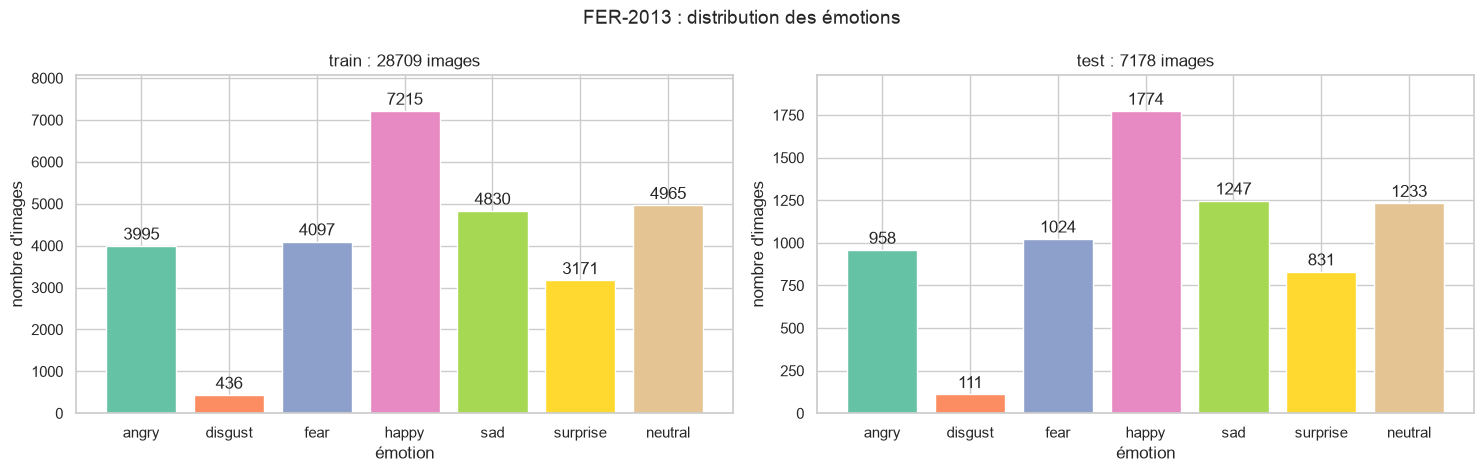

In [9]:
palette = sns.color_palette("Set2", NUM_CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, split in zip(axes, SPLITS):
    values = counts.loc[CLASS_NAMES, split]
    bars = ax.bar(CLASS_NAMES, values, color=palette)
    ax.bar_label(bars, padding=2)
    ax.set_title(f"{split} : {values.sum()} images")
    ax.set_xlabel("émotion")
    ax.set_ylabel("nombre d'images")
    ax.margins(y=0.12)

plt.suptitle("FER-2013 : distribution des émotions", fontsize=14)
plt.tight_layout()
plt.show()

Comparaison des deux distributions en pourcentage. Si les barres train et test sont à la même hauteur, le test est représentatif du train.

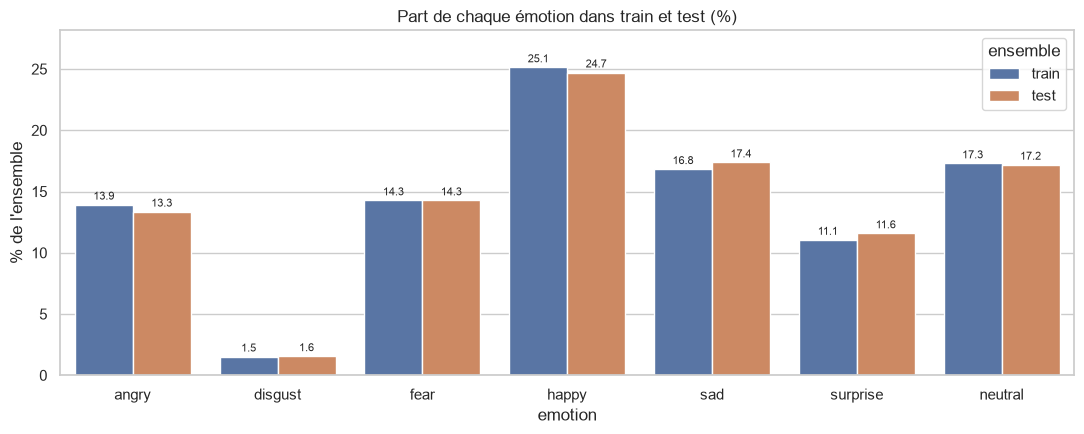

In [10]:
share_long = (
    class_share.reset_index(names="emotion")
    .melt(id_vars="emotion", var_name="ensemble", value_name="pourcentage")
)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=share_long, x="emotion", y="pourcentage", hue="ensemble", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
ax.set_title("Part de chaque émotion dans train et test (%)")
ax.set_ylabel("% de l'ensemble")
ax.margins(y=0.12)
plt.tight_layout()
plt.show()

### 1.8 Déséquilibre des classes

In [11]:
train_counts = counts.loc[CLASS_NAMES, "train"]

print(f"Classe majoritaire : {train_counts.idxmax()} ({train_counts.max()} images)")
print(f"Classe minoritaire : {train_counts.idxmin()} ({train_counts.min()} images)")
print(f"Ratio majoritaire / minoritaire : {train_counts.max() / train_counts.min():.1f}")

Classe majoritaire : happy (7215 images)
Classe minoritaire : disgust (436 images)
Ratio majoritaire / minoritaire : 16.5


Lecture :

- **happy** est la classe la plus représentée (environ un quart des images) ;
- **disgust** est très rare (environ 1,5 % des images) : le modèle la verra peu et aura du mal à la reconnaître ;
- les proportions sont quasiment identiques entre train et test, donc le test reflète bien la distribution d'entraînement.

Conséquences pour la suite : l'accuracy globale ne suffira pas (un modèle peut l'augmenter en ignorant `disgust`). En partie 5, on regardera la précision, le rappel et le F1 par classe, et la matrice de confusion. Des poids de classe sont préparés en 1.14 pour une éventuelle expérience.

### 1.9 Format des images

On lit toutes les images sans conversion (`IMREAD_UNCHANGED`) pour vérifier leur extension, leurs dimensions et leur type de pixels.

In [12]:
all_paths = [path for split in SPLITS for paths in image_paths[split].values() for path in paths]

formats = Counter()
for path in all_paths:
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
        formats[(path.suffix.lower(), "illisible", "")] += 1
    else:
        formats[(path.suffix.lower(), image.shape, str(image.dtype))] += 1

pd.DataFrame(
    [(ext, str(shape), dtype, n) for (ext, shape, dtype), n in formats.items()],
    columns=["extension", "shape", "dtype", "images"],
)

,extension,shape,dtype,images
0,.jpg,"(48, 48)",uint8,35887


Toutes les images sont des JPEG **48×48 à un seul canal** (niveaux de gris), pixels entiers `uint8` entre 0 et 255.

### 1.10 Exemples par émotion

Six images tirées au hasard dans le train pour chaque émotion. On voit déjà des cas difficiles : visages de profil, mains devant le visage, filigranes, expressions peu marquées.

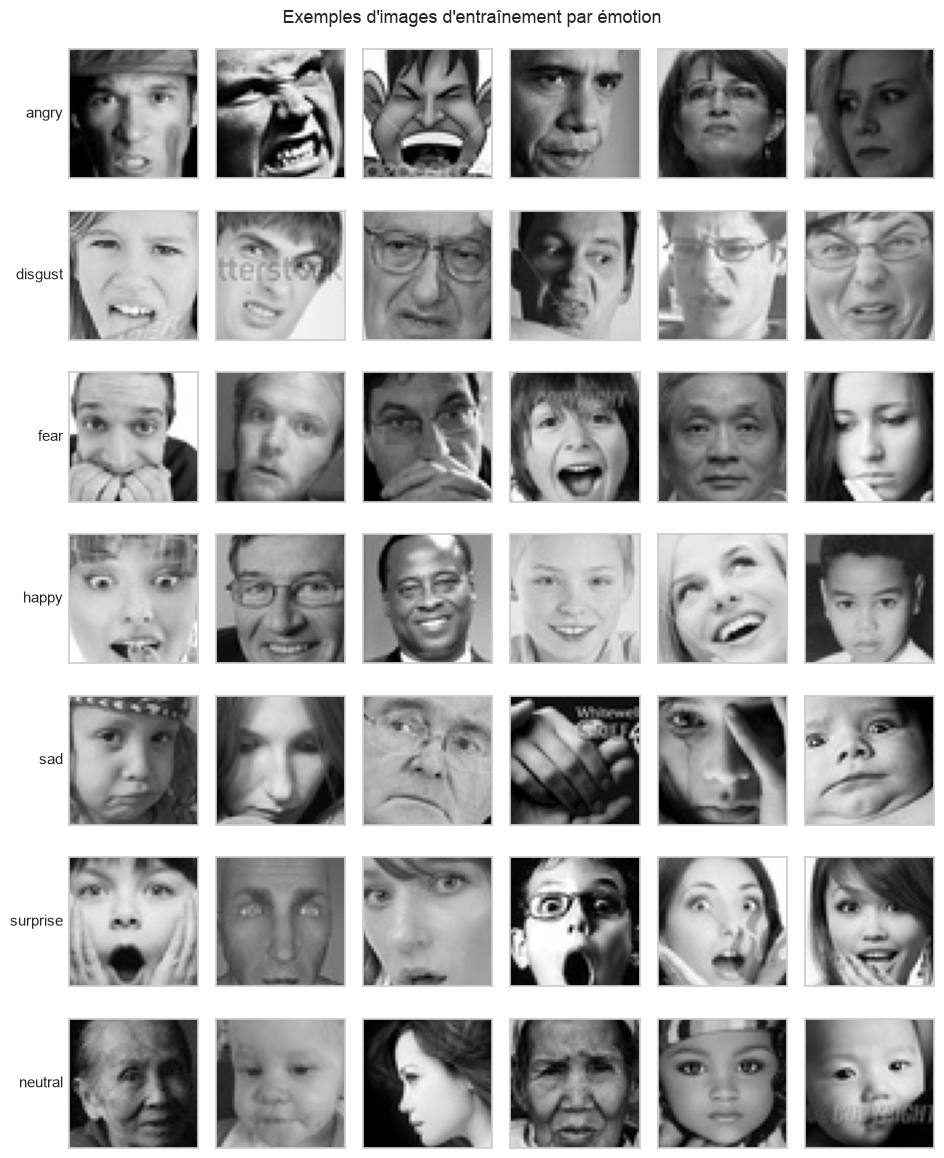

In [13]:
rng = np.random.default_rng(SEED)
n_examples = 6

fig, axes = plt.subplots(NUM_CLASSES, n_examples, figsize=(n_examples * 1.6, NUM_CLASSES * 1.7))
for row, name in enumerate(CLASS_NAMES):
    picks = rng.choice(len(image_paths["train"][name]), size=n_examples, replace=False)
    for col, index in enumerate(picks):
        ax = axes[row, col]
        image = cv2.imread(str(image_paths["train"][name][index]), cv2.IMREAD_GRAYSCALE)
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=11)

plt.suptitle("Exemples d'images d'entraînement par émotion", fontsize=13)
plt.tight_layout()
plt.show()

### 1.11 Prétraitement : `preprocess_face`

Chaque image passe par la même fonction, à l'entraînement comme plus tard sur les visages détectés dans une photo ou une vidéo. C'est ce qui garantit que le modèle voit toujours des entrées comparables.

| Étape | Rôle |
| --- | --- |
| Niveaux de gris | Une seule information de luminosité par pixel, comme dans FER-2013. Un visage en couleur venant d'une caméra est converti. |
| Redimensionnement 48×48 | Un réseau attend une taille d'entrée fixe. FER-2013 est déjà en 48×48, mais un visage détecté plus tard ne le sera pas. |
| Normalisation `/ 255` | Les pixels passent de [0, 255] à [0, 1]. Des entrées petites et de même échelle stabilisent la descente de gradient. |
| Ajout d'un canal | Keras attend une image sous la forme (hauteur, largeur, canaux) : ici (48, 48, 1). |

Pourquoi OpenCV + NumPy plutôt que `keras.utils.image_dataset_from_directory` ? Le jeu tient en mémoire (quelques centaines de Mo), on peut tout inspecter facilement, et la même fonction OpenCV servira aux visages extraits d'une vidéo.

In [14]:
def preprocess_face(image):
    """Image de visage (gris ou BGR, taille quelconque) -> tableau (48, 48, 1) float32 dans [0, 1]."""
    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    if image.shape[:2] != IMAGE_SIZE:
        image = cv2.resize(image, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
    image = image.astype("float32") / 255.0
    return image[..., np.newaxis]

Effet de la fonction sur une image :

In [15]:
raw = cv2.imread(str(image_paths["train"]["happy"][0]), cv2.IMREAD_GRAYSCALE)
processed = preprocess_face(raw)

print(f"avant : shape {raw.shape}, dtype {raw.dtype}, min {raw.min()}, max {raw.max()}")
print(f"après : shape {processed.shape}, dtype {processed.dtype}, min {processed.min():.3f}, max {processed.max():.3f}")

avant : shape (48, 48), dtype uint8, min 0, max 255
après : shape (48, 48, 1), dtype float32, min 0.000, max 1.000


### 1.12 Chargement des images

Pour chaque ensemble, on lit chaque image avec OpenCV, on applique `preprocess_face`, et on associe le label entier de son dossier (`happy` → 3, etc.). On obtient :

- `X` : tableau de forme (nombre d'images, 48, 48, 1) ;
- `y` : tableau d'entiers entre 0 et 6.

Le chargement prend quelques secondes.

In [16]:
def load_split(split):
    images, labels = [], []
    for name in CLASS_NAMES:
        for path in image_paths[split][name]:
            image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
            images.append(preprocess_face(image))
            labels.append(CLASS_TO_INDEX[name])
    return np.stack(images), np.array(labels, dtype="int64")

In [17]:
X_train_full, y_train_full = load_split("train")
X_test, y_test = load_split("test")

In [18]:
for name, X, y in [("train complet", X_train_full, y_train_full), ("test", X_test, y_test)]:
    print(f"{name:14s} X {X.shape} {X.dtype}  pixels [{X.min():.1f}, {X.max():.1f}]  y {y.shape} labels {np.unique(y)}")

print(f"Mémoire occupée par les images : {(X_train_full.nbytes + X_test.nbytes) / 1e6:.0f} Mo")

train complet  X (28709, 48, 48, 1) float32  pixels [0.0, 1.0]  y (28709,) labels [0 1 2 3 4 5 6]
test           X (7178, 48, 48, 1) float32  pixels [0.0, 1.0]  y (7178,) labels [0 1 2 3 4 5 6]
Mémoire occupée par les images : 331 Mo


### 1.13 Découpage train / validation / test

Rôle de chaque ensemble :

- **train** : le modèle apprend ses poids dessus ;
- **validation** : on suit le surapprentissage et on compare les réglages (architecture, learning rate, Dropout, Early Stopping…) ;
- **test** : évaluation finale, **une seule fois**, sur le modèle choisi. Il ne sert jamais à choisir un réglage, sinon le score final serait optimiste.

FER-2013 ne fournit que `train` et `test`. On prélève donc **20 % du train** comme validation. Le découpage est **stratifié** : chaque émotion garde la même proportion dans train et validation, ce qui compte pour une classe rare comme `disgust`. `random_state` rend le découpage reproductible.

In [19]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=SEED,
)

print("train      :", X_train.shape, y_train.shape)
print("validation :", X_val.shape, y_val.shape)
print("test       :", X_test.shape, y_test.shape)

train      : (22967, 48, 48, 1) (22967,)
validation : (5742, 48, 48, 1) (5742,)
test       : (7178, 48, 48, 1) (7178,)


Vérification : taille de chaque ensemble et part de chaque émotion. Les trois colonnes de pourcentages doivent être presque identiques.

In [20]:
final_sets = {"train": y_train, "validation": y_val, "test": y_test}

distribution = pd.DataFrame(
    {name: np.bincount(y, minlength=NUM_CLASSES) for name, y in final_sets.items()},
    index=CLASS_NAMES,
)
distribution_pct = (distribution / distribution.sum() * 100).round(2).add_suffix(" %")

pd.concat([distribution, distribution_pct], axis=1)

,train,validation,test,train %,validation %,test %
angry,3196,799,958,13.92,13.92,13.35
disgust,349,87,111,1.52,1.52,1.55
fear,3277,820,1024,14.27,14.28,14.27
happy,5772,1443,1774,25.13,25.13,24.71
sad,3864,966,1247,16.82,16.82,17.37
surprise,2537,634,831,11.05,11.04,11.58
neutral,3972,993,1233,17.29,17.29,17.18


In [21]:
sizes = pd.Series({name: len(y) for name, y in final_sets.items()})
pd.DataFrame({"images": sizes, "pourcentage du total": (sizes / sizes.sum() * 100).round(2)})

,images,pourcentage du total
train,22967,64.0
validation,5742,16.0
test,7178,20.0


Répartition finale : environ **64 % train, 16 % validation, 20 % test**.

### 1.14 Encodage des labels

Les labels sont des entiers (0 à 6). Deux encodages sont possibles avec Keras :

- **entiers** + perte `sparse_categorical_crossentropy` : c'est notre choix, plus léger ;
- **one-hot** + perte `categorical_crossentropy` : chaque label devient un vecteur de 7 valeurs avec un seul 1.

Les deux donnent exactement la même perte. Exemple d'équivalence :

In [22]:
example_labels = y_train[:5]
one_hot = np.eye(NUM_CLASSES, dtype="float32")[example_labels]

pd.DataFrame(one_hot.astype(int), columns=CLASS_NAMES, index=[CLASS_NAMES[i] for i in example_labels])

,angry,disgust,fear,happy,sad,surprise,neutral
neutral,0,0,0,0,0,0,1
happy,0,0,0,1,0,0,0
neutral,0,0,0,0,0,0,1
fear,0,0,1,0,0,0,0
surprise,0,0,0,0,0,1,0


Poids de classe : pour compenser le déséquilibre, Keras peut donner plus d'importance aux erreurs sur les classes rares (`model.fit(..., class_weight=class_weight)`). On les calcule ici sur le train seulement. Leur usage sera une expérience de la partie 6, comparée au modèle sans poids.

In [23]:
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(weights))

pd.Series(weights, index=CLASS_NAMES, name="poids").round(2)

angry       1.03
disgust     9.40
fear        1.00
happy       0.57
sad         0.85
surprise    1.29
neutral     0.83
Name: poids, dtype: float64

### 1.15 Bilan de la préparation

Contrôle des entrées prêtes pour Keras :

In [24]:
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:] == (*IMAGE_SIZE, 1)
assert X_train.dtype == np.float32 and 0.0 <= X_train.min() and X_train.max() <= 1.0
assert set(np.unique(y_train)) == set(range(NUM_CLASSES))

INPUT_SHAPE = X_train.shape[1:]
print("Entrée du réseau :", INPUT_SHAPE, "| classes :", NUM_CLASSES)

Entrée du réseau : (48, 48, 1) | classes : 7


Les données sont prêtes :

- `X_train`, `y_train` : apprentissage ;
- `X_val`, `y_val` : `validation_data` de `model.fit` ;
- `X_test`, `y_test` : évaluation finale uniquement ;
- `INPUT_SHAPE = (48, 48, 1)` et `NUM_CLASSES = 7` pour construire les modèles ;
- `preprocess_face` : prétraitement à réutiliser pour tout nouveau visage.

## Partie 2 — MLP de référence

Image, Flatten, Dense, Softmax. Point de comparaison avec le CNN.

## Partie 3 — CNN

Architecture justifiée. Tableau des dimensions et du nombre de paramètres couche par couche.

## Partie 4 — Entraînement

Perte, optimiseur, batch size, époques, métriques. Courbes de loss et d'accuracy, train et validation.

## Partie 5 — Évaluation et erreurs

Matrice de confusion, métriques par expression, exemples vraie classe / classe prédite / probabilité, analyse des confusions.

## Partie 6 — Expériences

Au moins trois expériences, une modification limitée à la fois. Tableau comparatif sur la validation, puis choix du modèle final.

## Parties 7 à 9 — Enrichissement, plusieurs visages, vidéo

Image ou frame, détection des visages, extraction, même prétraitement que l'entraînement, expression et probabilité pour chaque visage.